<a href="https://colab.research.google.com/github/EnzoBelfort/Modelagem-Computacional/blob/main/Segmenta%C3%A7%C3%A3o_com_SAM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install ultralytics opencv-python matplotlib

In [ ]:
import urllib.request

image_url = "https://raw.githubusercontent.com/EnzoBelfort/Modelagem-Computacional/main/src/pluma.jpeg"
IMAGE_PATH = "fumaca.jpg"

urllib.request.urlretrieve(image_url, IMAGE_PATH)

('fumaca.jpg', <http.client.HTTPMessage at 0x7a2912e5b1d0>)

## Segmentação Automática (Tudo)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.

image 1/1 /content/fumaca.jpg: 1024x1024 1 0, 1 1, 1 2, 1 3, 1 4, 1 5, 1 6, 1 7, 1 8, 1 9, 1 10, 1 11, 1 12, 1 13, 1 14, 1 15, 1 16, 1 17, 1 18, 1 19, 1 20, 1 21, 1 22, 1 23, 1 24, 1 25, 1 26, 1 27, 1 28, 1 29, 1 30, 1 31, 1 32, 1 33, 1 34, 1 35, 1 36, 1 37, 1 38, 1 39, 1 40, 1 41, 1 42, 1 43, 1 44, 341031.4ms
Speed: 46.0ms preprocess, 341031.4ms inference, 302.8ms postprocess per image at shape (1, 3, 1024, 1024)


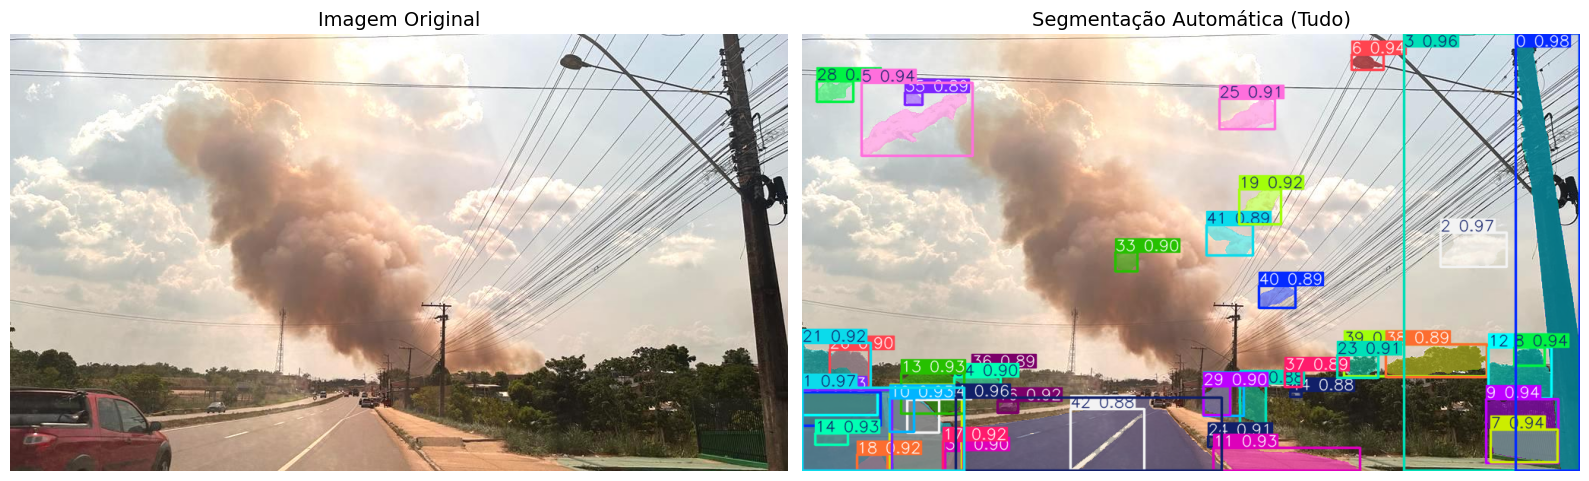

In [ ]:
import cv2
import matplotlib.pyplot as plt
from ultralytics import SAM

model = SAM("sam_b.pt")

results = model(IMAGE_PATH)

img_orig = cv2.imread(IMAGE_PATH)
img_orig = cv2.cvtColor(img_orig, cv2.COLOR_BGR2RGB)

img_com_mascaras = results[0].plot()
img_com_mascaras = cv2.cvtColor(img_com_mascaras, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

axes[0].imshow(img_orig)
axes[0].set_title("Imagem Original", fontsize=14)
axes[0].axis("off")

axes[1].imshow(img_com_mascaras)
axes[1].set_title("Segmentação Automática (Tudo)", fontsize=14)
axes[1].axis("off")

plt.tight_layout()
plt.show()

## Análise da segmentação:
O modelo de segmentação automática praticamente não cobre a pluma e não consegue classificar e segmentar quase nenhuma área dela e, em vez disso, segmentou diversos outros objetos da imagem. O modelo chega, inclusive, a segmentar algumas partes das nuvens próximas a pluma, porém ignora a pluma de fumaça em si por conta de:
- Ausência de Bordas Claras (Falta de Contraste): a fumaça não possui limites físicos definidos (como um carro ou um poste têm), o que confunde o algoritmo de detecção de bordas do SAM.
- Semelhança com Nuvens: A textura e o brilho da fumaça sob a luz solar são extremamente parecidos com os das nuvens ao fundo, fazendo com que o modelo falhe em separá-las.
- Ruído Visual: O emaranhado de cabos elétricos e postes de energia que cortam a imagem em primeiro plano dividiu visualmente a pluma.

## Configuração 1 (Bounding Box)


image 1/1 /content/fumaca.jpg: 1024x1024 1 0, 31292.6ms
Speed: 32.0ms preprocess, 31292.6ms inference, 3.5ms postprocess per image at shape (1, 3, 1024, 1024)


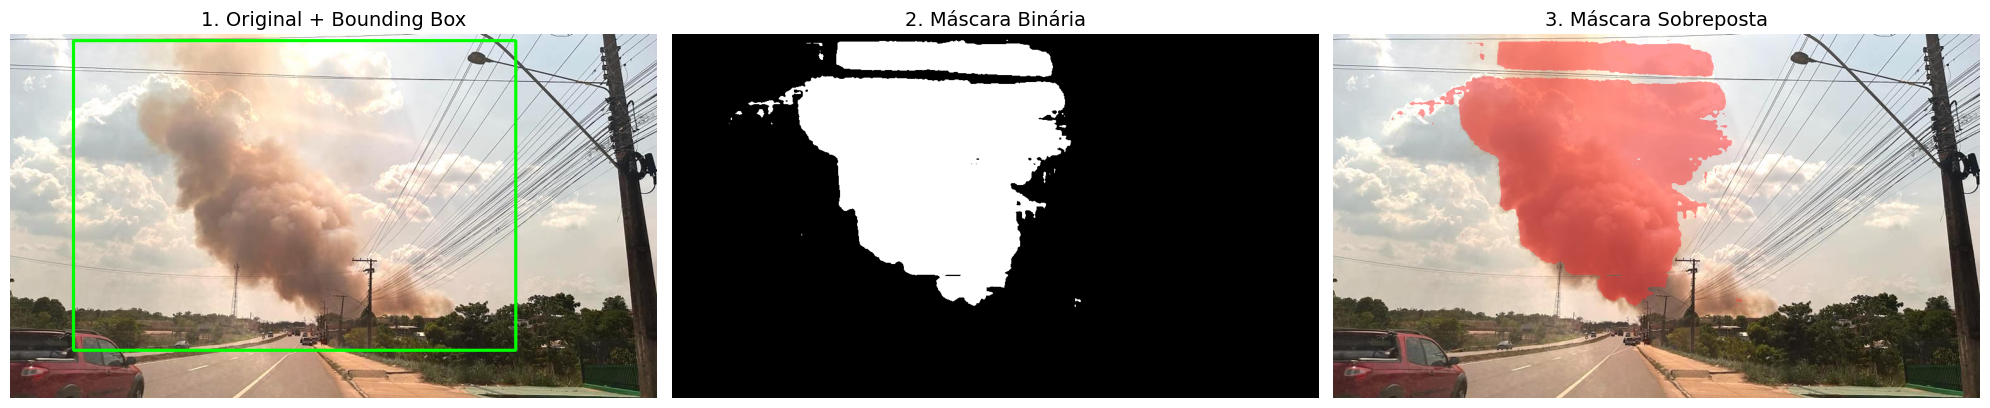

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import SAM

model = SAM("sam_b.pt")
IMAGE_PATH = "fumaca.jpg"

# Formato: [x_min, y_min, x_max, y_max]
bbox = [100, 10, 800, 500]

results = model(IMAGE_PATH, bboxes=bbox)

img_orig = cv2.imread(IMAGE_PATH)
img_orig = cv2.cvtColor(img_orig, cv2.COLOR_BGR2RGB)

img_com_box = img_orig.copy()
cv2.rectangle(img_com_box, (bbox[0], bbox[1]), (bbox[2], bbox[3]), (0, 255, 0), 4)

mask_tensor = results[0].masks.data[0]
mask_binary = mask_tensor.cpu().numpy()

overlay = img_orig.copy()
cor_mascara = np.array([255, 50, 50])
overlay[mask_binary == 1] = overlay[mask_binary == 1] * 0.5 + cor_mascara * 0.5

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

axes[0].imshow(img_com_box)
axes[0].set_title("1. Original + Bounding Box", fontsize=14)
axes[0].axis("off")

axes[1].imshow(mask_binary, cmap="gray")
axes[1].set_title("2. Máscara Binária", fontsize=14)
axes[1].axis("off")

axes[2].imshow(overlay)
axes[2].set_title("3. Máscara Sobreposta", fontsize=14)
axes[2].axis("off")

plt.tight_layout()
plt.show()

## Análise da segmentação:
O modelo com a bounding box parou de segmentar objetos irrelevantes como os postes, a rodovia, os carros e focou mais na pluma em si, porem o modelo tambem acabou unindo a fumaça com as nuvens como uma coisa só, por conta de suas semelhanças.
Como a transição entre a fumaça e as nuvens tem um gradiente de contraste muito suave, o modelo SAM tem dificuldade em encontrar as bordas que separam os dois objetos. Então a máscara binária ainda sofre pequenas contaminações das nuvens dentro da caixa e, além disso, o modelo, por conta dos poste e fios elétricos, acaba não incluindo a parte mais baixa da pluma.

## Configuração 2 (Pontos Positivos)


image 1/1 /content/fumaca.jpg: 1024x1024 1 0, 1 1, 30839.0ms
Speed: 17.4ms preprocess, 30839.0ms inference, 6.0ms postprocess per image at shape (1, 3, 1024, 1024)


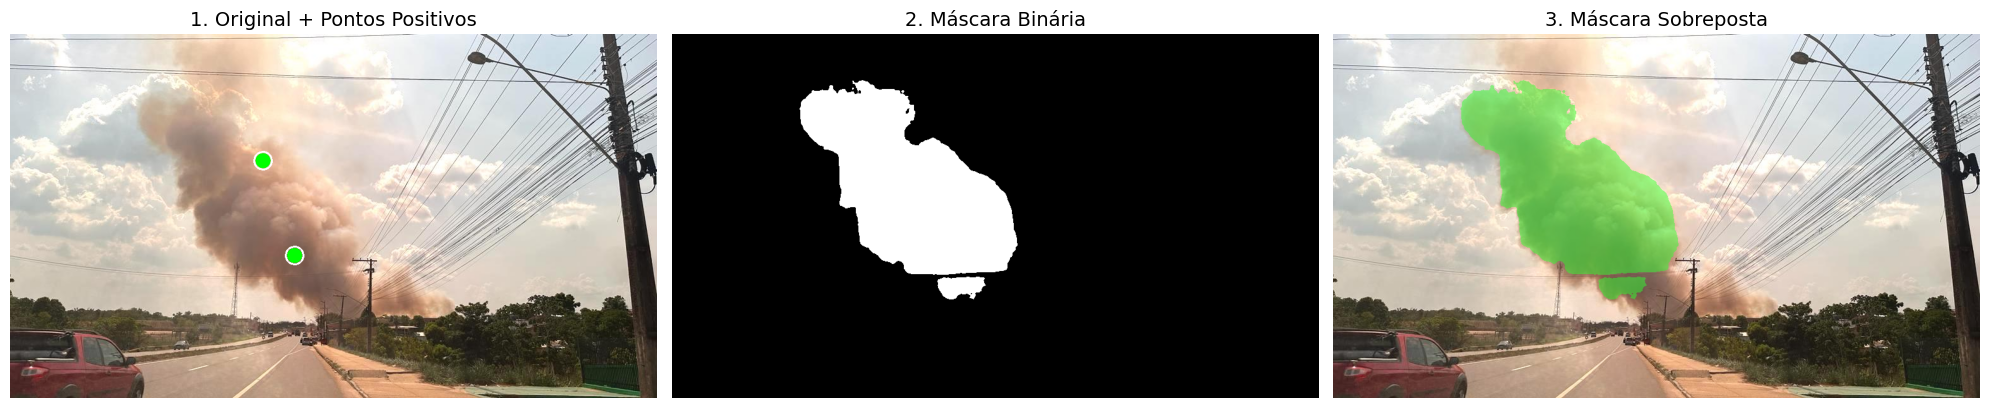

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import SAM

model = SAM("sam_b.pt")
IMAGE_PATH = "fumaca.jpg"

# Coordenadas (x, y) na área mais escura/densa da fumaça
pontos = [[450, 350], [400, 200]]
labels = [1, 1]

results = model(IMAGE_PATH, points=pontos, labels=labels)

img_orig = cv2.imread(IMAGE_PATH)
img_orig = cv2.cvtColor(img_orig, cv2.COLOR_BGR2RGB)

img_com_pontos = img_orig.copy()
for p in pontos:
    cv2.circle(img_com_pontos, (p[0], p[1]), 12, (0, 255, 0), -1)
    cv2.circle(img_com_pontos, (p[0], p[1]), 14, (255, 255, 255), 2) # Borda branca

mask_tensor = results[0].masks.data[0]
mask_binary = mask_tensor.cpu().numpy()

overlay = img_orig.copy()
cor_mascara = np.array([50, 255, 50])
overlay[mask_binary == 1] = overlay[mask_binary == 1] * 0.5 + cor_mascara * 0.5

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

axes[0].imshow(img_com_pontos)
axes[0].set_title("1. Original + Pontos Positivos", fontsize=14)
axes[0].axis("off")

axes[1].imshow(mask_binary, cmap="gray")
axes[1].set_title("2. Máscara Binária", fontsize=14)
axes[1].axis("off")

axes[2].imshow(overlay)
axes[2].set_title("3. Máscara Sobreposta", fontsize=14)
axes[2].axis("off")

plt.tight_layout()
plt.show()

## Analise da segmentação
Ao contrário da Bounding Box, que restringe de fora para dentro, o uso de pontos positivos faz o algoritmo "crescer" a máscara de dentro para fora, buscando pixels com similaridade em cor, contraste e textura a partir dos pontos plantados no centro da pluma. Isso, praticamente, reduziu para 0 a porcentagem de nuvens segmentadas também em conjunto com a pluma.

- Problema de Sub-segmentação: Como o interior da fumaça é bastante denso, o modelo interrompe o crescimento da máscara antes da hora, tanto para cima quanto para baixo. Ele identifica bem o núcleo da fumaça como um objeto único, mas deixa grande parte da fumaça das bordas totalmente de fora da máscara binária.

- Influência da iluminação: A parte superior da pluma está fortemente retroiluminada pelo sol, o que torna seus pixels brancos e brilhantes. O SAM interpreta essa mudança drástica de iluminação como a borda de um objeto novo, interrompendo a máscara e perdendo o topo da pluma.

- Interferência dos obstáculos: O feixe de fios elétricos atua como uma barreira física dura de forte contraste. Quando o algoritmo de expansão da máscara atinge as linhas pretas dos fios, ele "para" de crescer para aquele lado, criando buracos na segmentação.

## Configuração 3 (Pontos Positivos + Negativos)


image 1/1 /content/fumaca.jpg: 1024x1024 1 0, 1 1, 1 2, 1 4, 32629.7ms
Speed: 11.6ms preprocess, 32629.7ms inference, 11.9ms postprocess per image at shape (1, 3, 1024, 1024)


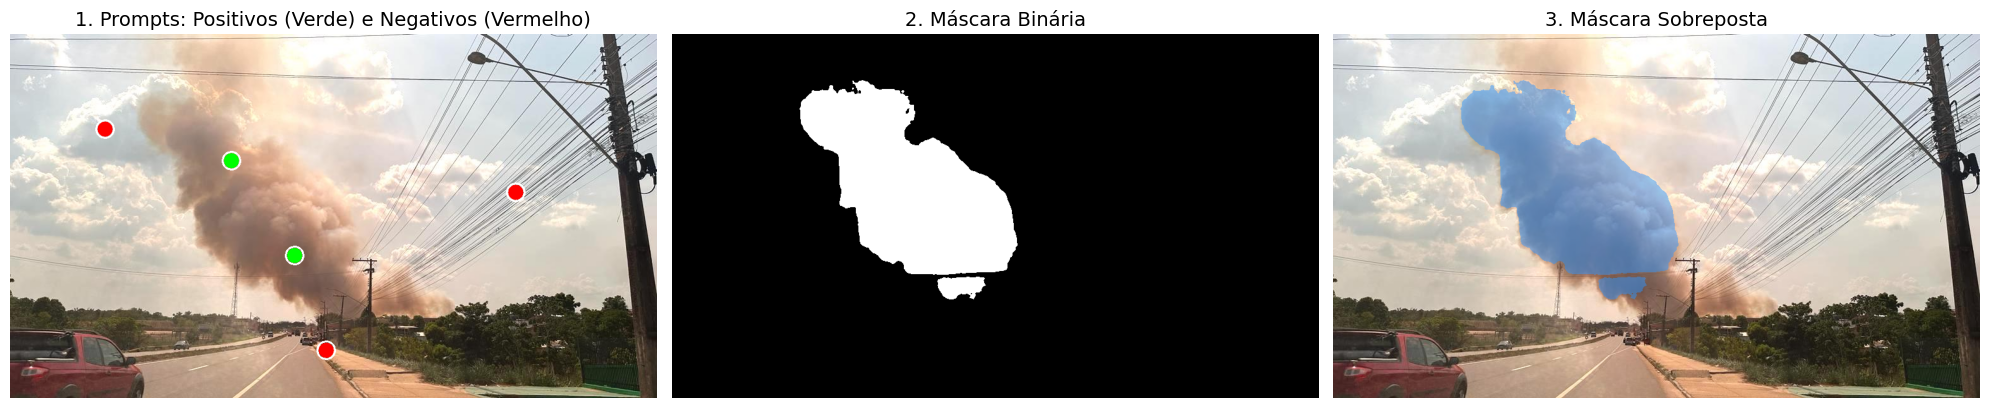

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import SAM

model = SAM("sam_b.pt")
IMAGE_PATH = "fumaca.jpg"

pontos = [
    [450, 350],  # Positivo: Centro denso da fumaça
    [350, 200],  # Positivo: Topo e expansão da pluma
    [150, 150],  # Negativo: Nuvem clara à esquerda
    [800, 250],  # Negativo: Céu cortado por fios à direita
    [500, 500]   # Negativo: Vegetação e asfalto na base
]

# Labels: 1 (Positivo/Incluir) e 0 (Negativo/Excluir)
labels = [1, 1, 0, 0, 0]

results = model(IMAGE_PATH, points=pontos, labels=labels)

img_orig = cv2.imread(IMAGE_PATH)
img_orig = cv2.cvtColor(img_orig, cv2.COLOR_BGR2RGB)

img_com_pontos = img_orig.copy()
for p, l in zip(pontos, labels):
    cor = (0, 255, 0) if l == 1 else (255, 0, 0)
    cv2.circle(img_com_pontos, (p[0], p[1]), 12, cor, -1)
    cv2.circle(img_com_pontos, (p[0], p[1]), 14, (255, 255, 255), 2)

mask_tensor = results[0].masks.data[0]
mask_binary = mask_tensor.cpu().numpy()

overlay = img_orig.copy()
cor_mascara = np.array([50, 150, 255])
overlay[mask_binary == 1] = overlay[mask_binary == 1] * 0.5 + cor_mascara * 0.5

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

axes[0].imshow(img_com_pontos)
axes[0].set_title("1. Prompts: Positivos (Verde) e Negativos (Vermelho)", fontsize=14)
axes[0].axis("off")

axes[1].imshow(mask_binary, cmap="gray")
axes[1].set_title("2. Máscara Binária", fontsize=14)
axes[1].axis("off")

axes[2].imshow(overlay)
axes[2].set_title("3. Máscara Sobreposta", fontsize=14)
axes[2].axis("off")

plt.tight_layout()
plt.show()

## Análise da segmentação:
O uso de pontos negativos nas nuvens não modificou significativamente a precisão da máscara nas bordas superiores, uma vez que apenas com os pontos positvos, o modelo obteve uma máscara similar/igual.
- A semelhança matemática entre as bordas da fumaça dissipada e as nuvens de fundo continua sendo um limitador. Como a fumaça nas bordas é rala, a cor do céu atravessa a pluma. O modelo, agora instruído a rejeitar o céu, ainda corta partes reais da fumaça onde essa transparência é muito olhida.
- Impacto da Iluminação e Obstáculos: A retroiluminação solar na parte superior cria um brilho intenso que o SAM confunde com o branco brilhante da nuvem marcada como "negativa", fragmentando a máscara nessa zona de transição. Adicionalmente, os fios elétricos agem como cortes físicos na imagem. Como o algoritmo procura continuidade de pixels, os cabos pretos que cruzam a pluma rompem essa continuidade, criando buracos na máscara binária onde a rede elétrica sobrepõe a fumaça.

- Os dois pontos verdes (positivos) foram colocados no centro e na expansão superior da pluma. A fumaça nessa região mais alta tem uma textura mais clara por causa do sol. Já a base da fumaça é muito mais escura e espessa. Como o SAM agrupa pixels por similaridade local, ele não encontrou semelhança suficiente para conectar o meio da pluma com a fumaça escura lá de baixo.   
- Barreiras de Contraste (Edge Detection): a máscara sobreposta em azul para de descer quase exatamente na linha onde a copa das árvores e os fios elétricos horizontais cruzam a fumaça. O algoritmo do SAM lê essas linhas escuras da vegetação e dos cabos como "bordas rígidas" e interrompe o crescimento da máscara ali, achando que o objeto acabou.   
- O peso do Ponto Negativo Inferior: O ponto vermelho que colocado na calçada cumpriu o papel de bloquear o asfalto, mas criou um "campo de repulsão". Como a fumaça escura na base se mistura visualmente com as árvores escuras do fundo, o SAM descartou toda aquela área por precaução para não incluir a vegetação.


image 1/1 /content/fumaca.jpg: 1024x1024 1 0, 1 1, 1 2, 1 3, 1 5, 33173.4ms
Speed: 11.5ms preprocess, 33173.4ms inference, 15.3ms postprocess per image at shape (1, 3, 1024, 1024)


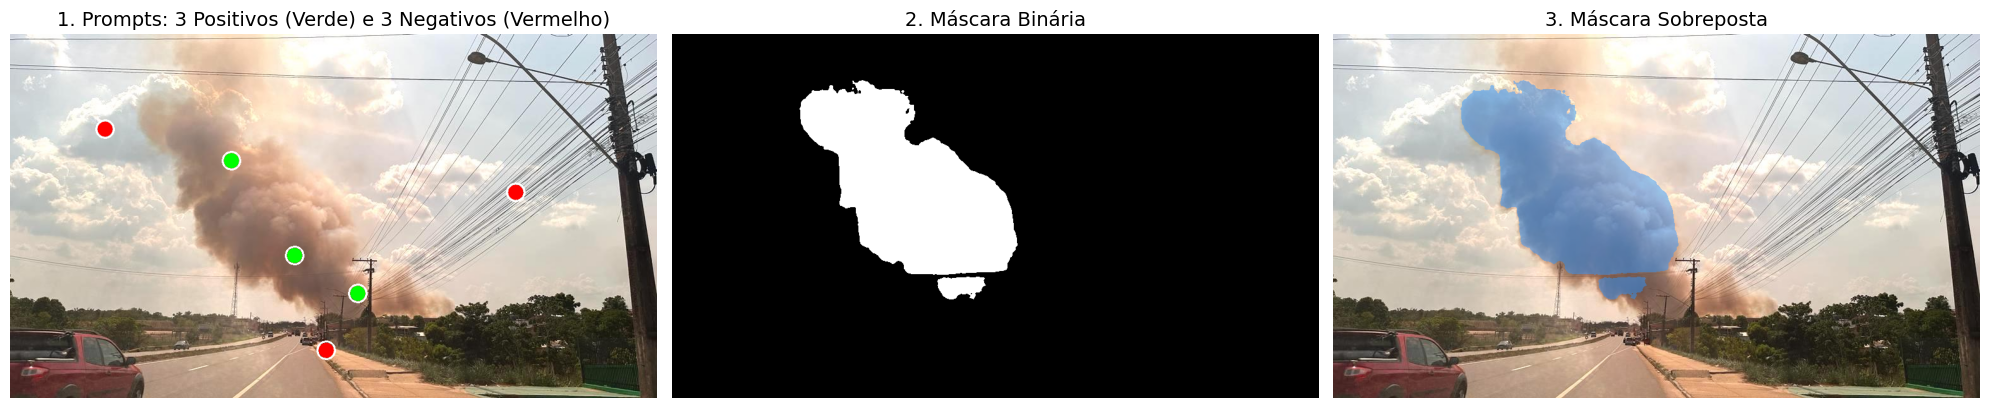

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import SAM

model = SAM("sam_b.pt")
IMAGE_PATH = "fumaca.jpg"

pontos = [
    [450, 350],  # Positivo 1: Centro denso da fumaça
    [350, 200],  # Positivo 2: Topo e expansão da pluma
    [550, 410],  # Positivo 3: Novo ponto
    [150, 150],  # Negativo 1: Nuvem clara à esquerda (fundo)
    [800, 250],  # Negativo 2: Céu cortado por fios à direita
    [500, 500]   # Negativo 3: Vegetação e asfalto na base
]

# Labels: 1 (Positivo/Incluir) e 0 (Negativo/Excluir)
labels = [1, 1, 1, 0, 0, 0]

results = model(IMAGE_PATH, points=pontos, labels=labels)

img_orig = cv2.imread(IMAGE_PATH)
img_orig = cv2.cvtColor(img_orig, cv2.COLOR_BGR2RGB)

img_com_pontos = img_orig.copy()
for p, l in zip(pontos, labels):
    cor = (0, 255, 0) if l == 1 else (255, 0, 0)
    cv2.circle(img_com_pontos, (p[0], p[1]), 12, cor, -1)
    cv2.circle(img_com_pontos, (p[0], p[1]), 14, (255, 255, 255), 2)

mask_tensor = results[0].masks.data[0]
mask_binary = mask_tensor.cpu().numpy()

overlay = img_orig.copy()
cor_mascara = np.array([50, 150, 255])
overlay[mask_binary == 1] = overlay[mask_binary == 1] * 0.5 + cor_mascara * 0.5

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

axes[0].imshow(img_com_pontos)
axes[0].set_title("1. Prompts: 3 Positivos (Verde) e 3 Negativos (Vermelho)", fontsize=14)
axes[0].axis("off")

axes[1].imshow(mask_binary, cmap="gray")
axes[1].set_title("2. Máscara Binária", fontsize=14)
axes[1].axis("off")

axes[2].imshow(overlay)
axes[2].set_title("3. Máscara Sobreposta", fontsize=14)
axes[2].axis("off")

plt.tight_layout()
plt.show()

Tentei adicionar um novo ponto positivo para o modelo detectar a parte inferior da pluma, porém a segmentação se manteve igual a anterior.

## Conclusão
Apesar das sucessivas iterações e do ajuste de coordenadas no prompt engineering (Configuração 3), o modelo SAM base demonstrou uma limitação estrutural ao tentar segmentar a base da pluma. O algoritmo falha devido a dois fatores principais:
1. Obstáculos Físicos e Quebra de Continuidade
2. Baixo Gradiente de Contraste